<a href="https://colab.research.google.com/github/miayon/CVPR/blob/main/CNN_22_49517_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# American International University-Bangladesh (AIUB)
## Department of Computer Science, Faculty of Science and Technology
### Course: Computer Vision & Pattern Recognition (CSC 4254)
---
# Assignment: CNN Development on Custom Dataset
* **Student ID:** 22-49517-3
* **Dataset:** Intel Image Classification (6 Natural Scene Classes)
* **Framework:** PyTorch & Torchvision

## 1. Import Libraries
Setup for PyTorch, torchvision, data loaders, and plotting. The random seed is set to 42 across PyTorch, NumPy, and Python's random module so dataset splits and weight initialization are reproducible.

In [11]:
!pip install -q kagglehub torchsummary

import os
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets
import torchvision.transforms as transforms
from torch.optim import SGD, Adam
from torchsummary import summary
import kagglehub

# Global seed for reproducible weight initialization and batch sampling
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Load and Explore Dataset
I used the Intel Image Classification dataset from Kaggle (`puneet6060/intel-image-classification`), which contains 14,034 training images and 3,000 test images across 6 scene categories: `buildings`, `forest`, `glacier`, `mountain`, `sea`, and `street`. Most images are 150x150 RGB.

In [12]:
path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Path to dataset files:", path)

train_folder = path + '/seg_train/seg_train'
test_folder = path + '/seg_test/seg_test'

print("Train Folder:", train_folder)
print("Test Folder :", test_folder)
print("Classes detected:", sorted(os.listdir(train_folder)))

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification
Train Folder: /kaggle/input/intel-image-classification/seg_train/seg_train
Test Folder : /kaggle/input/intel-image-classification/seg_test/seg_test
Classes detected: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


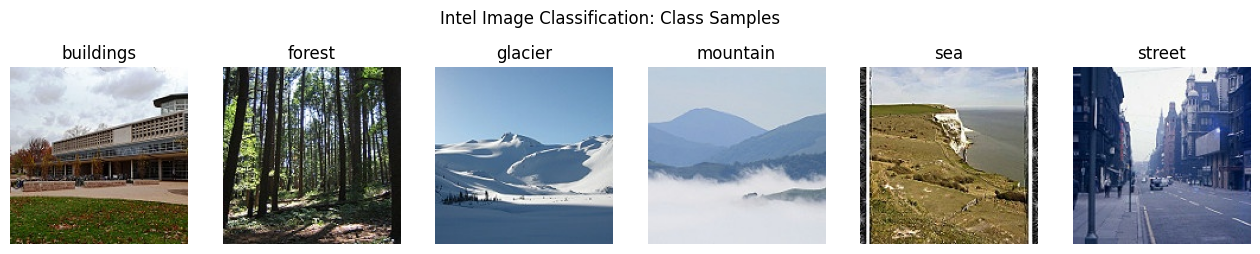

In [13]:
classes = sorted(os.listdir(train_folder))
fig, axes = plt.subplots(1, len(classes), figsize=(16, 3))

for idx, cls in enumerate(classes):
    cls_folder = train_folder + '/' + cls
    sample_img_name = os.listdir(cls_folder)[0]
    sample_img = plt.imread(cls_folder + '/' + sample_img_name)
    axes[idx].imshow(sample_img)
    axes[idx].set_title(cls)
    axes[idx].axis("off")

plt.suptitle("Intel Image Classification: Class Samples")
plt.show()

## 3. Data Preprocessing & Augmentation
Images are resized to 64x64 to speed up training on the T4 GPU while keeping the main scene structure intact, and `ToTensor()` scales the pixel values from [0, 255] to [0.0, 1.0]. For the training set (`seg_train`, 14,034 images), I applied `RandomHorizontalFlip`, `RandomRotation(15)`, and `ColorJitter` so the model generalizes better across different camera angles and lighting conditions. The validation and test sets use only deterministic resizing and tensor conversion. Since the original dataset only provides train and test folders, I split the 3,000 images in `seg_test` 50/50 into 1,500 validation samples and 1,500 test samples, and loaded all splits with a batch size of 32.

In [14]:
size = 64

# Training augmentation pipeline
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

# Deterministic transforms for validation and testing
val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

train_data = datasets.ImageFolder(train_folder, transform=train_transform)
val_test_data = datasets.ImageFolder(test_folder, transform=val_transform)

# 50/50 partition of test images: 1,500 validation / 1,500 test
val_size = len(val_test_data) // 2
test_size = len(val_test_data) - val_size

val_data, test_data = random_split(
    val_test_data,
    [val_size, test_size]
)

print("Dataset Summary")
print("Train Data: ", len(train_data))
print("Validation Data: ", len(val_data))
print("Test Data: ", len(test_data))
print("Classes and Indices: ", train_data.class_to_idx)
num_classes = len(train_data.classes)

batch_size = 32
learning_rate = 1e-3
epoch_number = 10

trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

Dataset Summary
Train Data:  14034
Validation Data:  1500
Test Data:  1500
Classes and Indices:  {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


## 4. Define CNN Architecture
The model is a 3-stage CNN built with `nn.Sequential`. The three convolutional blocks use 32, 64, and 128 filters (all with 3x3 kernels and `padding=1`) to extract progressively higher-level features from basic edges up to complex textures. Each convolution is followed by `ReLU` and a 2x2 `MaxPool2d` layer, which halves the spatial dimensions at each stage from 64x64 down to 8x8. The resulting 128x8x8 feature maps flatten into 8,192 units and feed into a 256-unit linear layer with `Dropout(0.5)` to prevent overfitting on the 2.09M dense parameters, followed by a final 6-unit output layer. I used `CrossEntropyLoss` and the `Adam` optimizer with a learning rate of 0.001.

In [15]:
def get_model():
    model = nn.Sequential(
        # Stage 1: 3x64x64 -> 32x32x32 (padding=1 preserves borders before 2x2 max pool)
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Stage 2: 32x32x32 -> 64x16x16
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Stage 3: 64x16x16 -> 128x8x8
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier: 128 * 8 * 8 = 8,192 flattened features
        nn.Flatten(),
        nn.Linear(128 * 8 * 8, 256),
        nn.ReLU(),
        nn.Dropout(0.5),  # p=0.5 regularization on 2M+ dense weights
        nn.Linear(256, num_classes)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, size, size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
              ReLU-2           [-1, 32, 64, 64]               0
         MaxPool2d-3           [-1, 32, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          18,496
              ReLU-5           [-1, 64, 32, 32]               0
         MaxPool2d-6           [-1, 64, 16, 16]               0
            Conv2d-7          [-1, 128, 16, 16]          73,856
              ReLU-8          [-1, 128, 16, 16]               0
         MaxPool2d-9            [-1, 128, 8, 8]               0
          Flatten-10                 [-1, 8192]               0
           Linear-11                  [-1, 256]       2,097,408
             ReLU-12                  [-1, 256]               0
          Dropout-13                  [-1, 256]               0
           Linear-14                   

## 5. Training Loop with Validation
The training process is split into `train_one_epoch` and `validation` functions. During training, `model.train()` keeps dropout active while iterating through batches, zeroing gradients, running backpropagation, and updating weights. During validation, `model.eval()` disables dropout and `@torch.no_grad()` turns off gradient tracking to save memory. Training for 10 epochs was sufficient for the loss to converge steadily without overfitting.

In [16]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [17]:
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/10] | Train Loss: 1.1344 | Train Accuracy: 55.36% | Val Loss: 0.9030 | Val Accuracy: 66.40%
Epoch [2/10] | Train Loss: 0.8403 | Train Accuracy: 68.69% | Val Loss: 0.7090 | Val Accuracy: 72.53%
Epoch [3/10] | Train Loss: 0.7486 | Train Accuracy: 73.12% | Val Loss: 0.6128 | Val Accuracy: 78.40%
Epoch [4/10] | Train Loss: 0.6729 | Train Accuracy: 75.64% | Val Loss: 0.6444 | Val Accuracy: 77.00%
Epoch [5/10] | Train Loss: 0.6452 | Train Accuracy: 76.66% | Val Loss: 0.5975 | Val Accuracy: 78.67%
Epoch [6/10] | Train Loss: 0.6021 | Train Accuracy: 78.43% | Val Loss: 0.6120 | Val Accuracy: 78.07%
Epoch [7/10] | Train Loss: 0.5737 | Train Accuracy: 79.48% | Val Loss: 0.5653 | Val Accuracy: 81.60%
Epoch [8/10] | Train Loss: 0.5512 | Train Accuracy: 80.01% | Val Loss: 0.5142 | Val Accuracy: 82.13%
Epoch [9/10] | Train Loss: 0.5328 | Train Accuracy: 81.15% | Val Loss: 0.5699 | Val Accuracy: 81.33%
Epoch [10/10] | Train Loss: 0.5067 | Train Accuracy: 81.99% | Val Loss: 0.5051 | Val Accura

## 6. Evaluate Model on Test Set
After training, I evaluate the model on the 1,500 test images, test a single sample image with its predicted confidence, and save the trained `state_dict` to `model.pth` (file size is 8.37 MB). I then reload the saved weights into a fresh model instance to verify that the reloaded model reproduces the exact test loss and accuracy.

In [18]:
test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f"Test Loss : {test_loss:0.4f} , Test Accuracy: {test_acc*100:0.2f}%")

Test Loss : 0.5040 , Test Accuracy: 82.20%


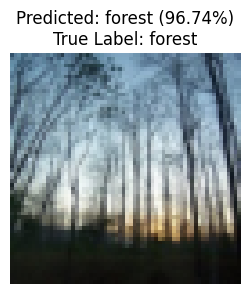

In [19]:
random_idx = np.random.randint(0, len(test_data))
test_img, true_label = test_data[random_idx]
img = test_img.view(-1, 3, size, size).to(device)

output = model(img)
pred = torch.exp(output) / torch.sum(torch.exp(output))
confidence, index = pred.max(-1)

plt.figure(figsize=(3, 3))
plt.imshow(test_img.view(3, size, size).permute(1, 2, 0))
plt.title(f"Predicted: {train_data.classes[index]} ({confidence.item()*100:0.2f}%)\nTrue Label: {train_data.classes[true_label]}")
plt.axis("off")
plt.show()

In [20]:
torch.save(model.state_dict(), 'model.pth')
print(f"Model saved to 'model.pth' ({os.path.getsize('model.pth') / (1024 * 1024):.2f} MB)")

# Reload into fresh instance to verify state_dict persistence
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('model.pth', map_location=device))
saved_model.eval()

reloaded_test_loss, reloaded_test_acc = validation(test_dl, saved_model, loss_fn)
print(f"Reloaded Model Test Loss: {reloaded_test_loss:0.4f} , Test Accuracy: {reloaded_test_acc*100:0.2f}%")

Model saved to 'model.pth' (8.37 MB)
Reloaded Model Test Loss: 0.5040 , Test Accuracy: 82.20%


## 7. Visualizations (Loss/Accuracy Curves)
I plot the training and validation loss and accuracy curves across all 10 epochs to observe how the model learns over time.

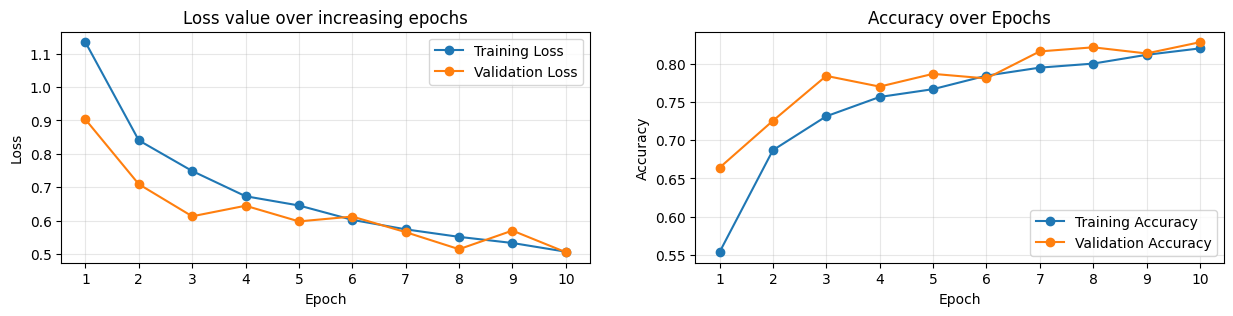

In [21]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))

plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 8. Analysis & Discussion of Results
Over the 10 epochs, training loss dropped from 1.1344 to 0.5067 while validation loss decreased from 0.9030 to 0.5051, tracking the training curve closely without diverging. Training accuracy rose from 55.36% to 81.99% and validation accuracy reached 82.80%. Validation accuracy stayed slightly above training accuracy in several epochs because `Dropout(0.5)` and random data augmentations are active during training but turned off during evaluation. On the held-out test set of 1,500 images, the model achieved 82.20% accuracy and 0.5040 loss. Most misclassifications happen between visually similar scenes, such as `glacier` vs. `mountain` (which both feature snow and rock) or `street` vs. `buildings` (which share urban facades and roads).

Combining data augmentation, 2x2 max pooling, and 50% dropout on the dense layer effectively regularized the 2.19M total parameters. Using a batch size of 32 and Adam (`lr=0.001`) on 64x64 inputs gave a good balance between fast epoch times and stable convergence.

## 9. Conclusions & Future Work
This custom 3-stage CNN achieved 82.20% test accuracy on the 6-class Intel Image Classification dataset while keeping the saved `model.pth` checkpoint compact at 8.37 MB. Reloading the state dictionary into a fresh model instance verified that the saved weights reproduce the exact same test loss and accuracy. To push accuracy higher in future iterations, I would experiment with residual skip connections (ResNet-style blocks), add a learning rate scheduler like `ReduceLROnPlateau` for finer late-epoch tuning, and increase the input resolution to 128x128 so the network can better separate similar classes like glaciers and mountains.